# Best fitted parabola

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

The general formula of a parabola is given by

$$y = Bx^2 + Cx + D$$

In [2]:
points = np.array([[-1,1/2],[1,-1],[2,-1/2],[3,2]])

points_x = points[:,0]
points_y = points[:,1]
points_x2 = points_x**2

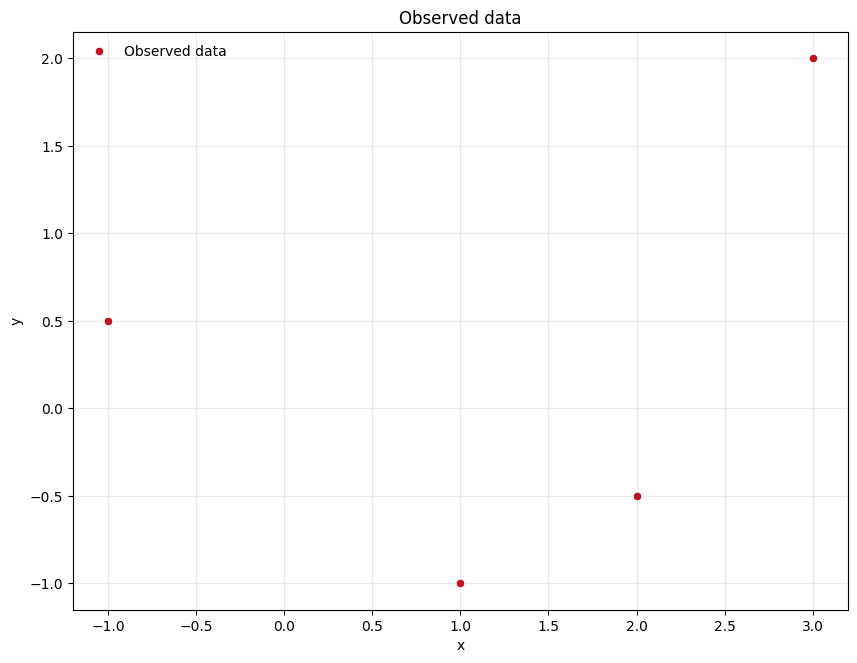

In [3]:
plt.figure(figsize=(10,7.5))
plt.plot(points_x, points_y, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Observed data')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

## Compute coefficients

In [4]:
n = len(points)
Y = points_y
X = np.vstack([points_x2, points_x, np.ones(n)]).T
p = X.shape[1]

B, C, D = np.linalg.lstsq(X, Y, rcond=None)[0]
params  = [B, C, D]

## Compute confidence and prediction intervals

In [5]:
alpha = 0.05

SSE = np.linalg.lstsq(X, Y, rcond=None)[1][0]

x_grid = np.linspace(-1.5, 3.5, 50)
X_grid = np.vstack([x_grid**2, x_grid, np.ones(len(x_grid))]).T

In [6]:
# Computing confidence interval
aux_t_conf = np.sqrt(SSE/(n-p)*(np.diag(X_grid @ np.linalg.inv(X.T @ X) @ X_grid.T)))
Y_grid_hat = X_grid @ params
ci_lower = Y_grid_hat-t.ppf(1-alpha/2,n-p)*aux_t_conf
ci_upper = Y_grid_hat+t.ppf(1-alpha/2,n-p)*aux_t_conf

# Computing prediction interval
aux_t_pred = np.sqrt(SSE/(n-p)*(1+np.diag(X_grid @ np.linalg.inv(X.T @ X) @ X_grid.T)))
Y_grid_hat = X_grid @ params
pi_lower = Y_grid_hat-t.ppf(1-alpha/2,n-p)*aux_t_pred
pi_upper = Y_grid_hat+t.ppf(1-alpha/2,n-p)*aux_t_pred

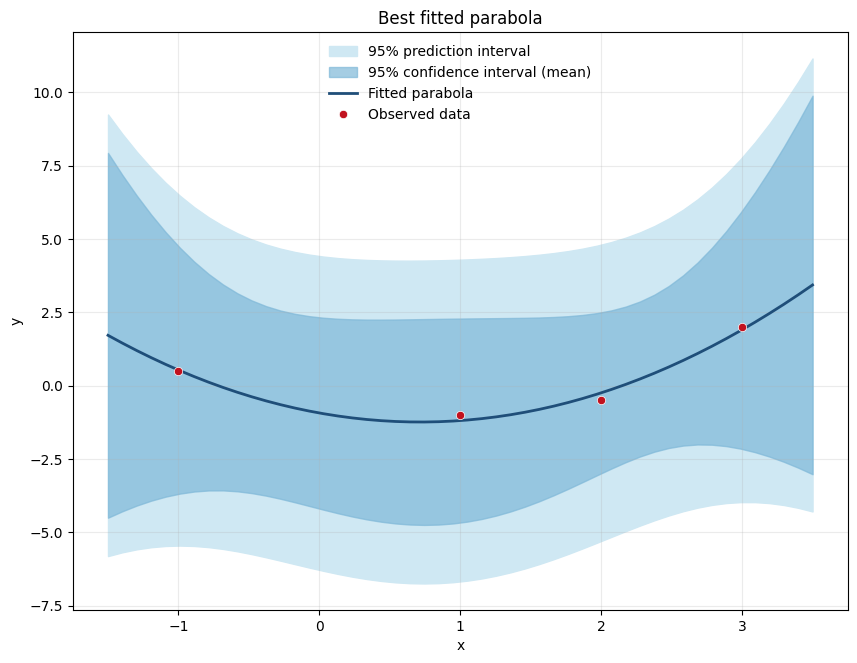

In [7]:
plt.figure(figsize=(10,7.5))

# Bands: light, low-saturation fills, ordered wide-to-narrow
ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'
plt.fill_between(x_grid, pi_lower, pi_upper, color='#cfe8f3', label=pi_label)
plt.fill_between(x_grid, ci_lower, ci_upper, color='#7fb8d8', alpha=0.7, label=ci_label)

# Fitted curve as a line, not markers — it's a model, not observations
plt.plot(x_grid, B*x_grid**2 + C*x_grid + D, color='#1f4e79', lw=2, label='Fitted parabola')

# Observed data on top, dark and distinct
plt.plot(points_x, points_y, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Best fitted parabola')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)